# dMRI Patch Gluing
Patch definition:
- Patches A and B overlap around the split point.
- A and B share exactly the same sampled overlap nodes.
- For visualization, a stitched map is made by drawing A on the left side of the split and B on the right side.
- The visualization uses a masked interpolated slice image.


In [1]:
# ── Safe imports and runtime settings ─────────────────────────────────────────
# These environment variables reduce thread oversubscription and make UMAP/t-SNE
# less likely to crash the notebook kernel on shared servers or macOS.
import os
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('NUMEXPR_NUM_THREADS', '1')
os.environ.setdefault('NUMBA_NUM_THREADS', '1')

import sys, json, gc, warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial import cKDTree
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap as umap_lib

warnings.filterwarnings('ignore', category=UserWarning)

project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

from utilities import KernelNN
from utilities_dMRI import dMRI_Graph_Generator

# Set this to False only if you specifically want to test MPS again.
# CUDA is still preferred automatically on Olivia / GPU nodes.
FORCE_CPU_ON_MPS = True

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available() and not FORCE_CPU_ON_MPS:
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print(f'Using device: {device}')
if torch.backends.mps.is_available() and FORCE_CPU_ON_MPS and not torch.cuda.is_available():
    print('MPS is available but disabled for stability. Set FORCE_CPU_ON_MPS=False if you want to test it.')


using Device: mps
Using device: cpu
MPS is available but disabled for stability. Set FORCE_CPU_ON_MPS=False if you want to test it.


In [2]:
# ── Helpers ───────────────────────────────────────────────────────────────────

def clear_cache():
    """Free Python + accelerator memory as much as possible."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if torch.backends.mps.is_available():
        try:
            torch.mps.empty_cache()
        except Exception:
            pass


def mean_pairwise_dist_np(x: np.ndarray, max_pairs: int = 20000, seed: int = 42) -> float:
    """
    Memory-safe mean pairwise distance.
    Avoids building a huge N x N torch.cdist matrix when overlap becomes large.
    """
    x = np.asarray(x, dtype=np.float32)
    n = x.shape[0]
    if n < 2:
        return np.nan

    total_pairs = n * (n - 1) // 2
    rng = np.random.default_rng(seed)

    if total_pairs <= max_pairs:
        diffs = x[:, None, :] - x[None, :, :]
        d = np.sqrt(np.sum(diffs ** 2, axis=-1))
        iu = np.triu_indices(n, k=1)
        return float(d[iu].mean())

    i = rng.integers(0, n, size=max_pairs)
    j = rng.integers(0, n, size=max_pairs)
    valid = i != j
    i, j = i[valid], j[valid]
    d = np.linalg.norm(x[i] - x[j], axis=1)
    return float(d.mean())


def get_region_mask(Generator, region: str) -> torch.Tensor:
    y, z = Generator.normed_coords[:, 1], Generator.normed_coords[:, 2]
    masks = {
        'frontal':     y > 0.60,
        'parietal':    (y > 0.35) & (y < 0.85) & (z > 0.62),
        'temporal':    (y > 0.20) & (y < 0.70) & (z < 0.55),
        'occipital':   y < 0.25,
        'subcortical': (y > 0.35) & (y < 0.65) & (z > 0.28) & (z < 0.58),
    }
    if region not in masks:
        raise ValueError(f'Unknown region: {region}')
    return masks[region]


def sample_shared_overlap(Generator, overlap_mask, N_ov_max):
    """
    Randomly sample at most N_ov_max voxels from the overlap region.
    The same indices are used by both A and B, so overlap nodes match exactly.
    """
    ov_all = torch.where(overlap_mask)[0]
    if len(ov_all) > N_ov_max:
        perm = torch.randperm(len(ov_all))[:N_ov_max]
        return ov_all[perm]
    return ov_all


def build_patch(Generator, patch_mask, overlap_mask, shared_ov_idx,
                N_total, k, perplexity, feature_mode, sigma_method):
    """
    Build a patch graph using the pre-sampled shared overlap nodes.
    The remaining quota is filled from the non-overlapping part of the patch.
    """
    orig_da, orig_coords = Generator.da, Generator.normed_coords

    rest_idx = torch.where(patch_mask & ~overlap_mask)[0]
    N_rest = max(0, min(N_total - len(shared_ov_idx), len(rest_idx)))

    if N_rest > 0:
        perm = torch.randperm(len(rest_idx))[:N_rest]
        all_idx = torch.cat([shared_ov_idx, rest_idx[perm]])
    else:
        all_idx = shared_ov_idx

    Generator.da = orig_da[all_idx]
    Generator.normed_coords = orig_coords[all_idx]

    graph = Generator.sample_graph(
        N=len(all_idx),
        k=k,
        perplexity=perplexity,
        sampling_method='random',
        gen_feature_mode=feature_mode,
        sigma_method=sigma_method,
    )

    Generator.da = orig_da
    Generator.normed_coords = orig_coords

    return graph.to(device)


def find_matched_overlap(coords_A, coords_B, sp, overlap_margin, split_axis, tol=1e-5):
    """Find index pairs for the same physical overlap voxels in graph A and graph B."""
    ov_A = ((coords_A[:, split_axis] >= sp - overlap_margin) &
            (coords_A[:, split_axis]  < sp + overlap_margin))
    ov_B = ((coords_B[:, split_axis] >= sp - overlap_margin) &
            (coords_B[:, split_axis]  < sp + overlap_margin))

    if ov_A.sum() == 0 or ov_B.sum() == 0:
        return np.array([], dtype=int), np.array([], dtype=int)

    dists, nn_idx = cKDTree(coords_B[ov_B]).query(coords_A[ov_A], k=1)
    exact = dists < tol
    idx_A = np.where(ov_A)[0][exact]
    idx_B = np.where(ov_B)[0][nn_idx[exact]]
    return idx_A, idx_B


def compute_nmse(emb_A, emb_B, idx_A, idx_B):
    """
    NMSE = mean(||z_A - z_B||^2) / mean_pairwise_dist(E_overlap_A)^2
    Uses a memory-safe pairwise-distance estimate.
    """
    if len(idx_A) < 2:
        return float('nan'), float('nan'), 0

    E_A = np.asarray(emb_A[idx_A], dtype=np.float32)
    E_B = np.asarray(emb_B[idx_B], dtype=np.float32)

    mse = float(np.mean(np.sum((E_A - E_B) ** 2, axis=1)))
    mpd = mean_pairwise_dist_np(E_A)
    nmse = mse / (mpd ** 2 + 1e-12)
    return mse, nmse, len(idx_A)


def preprocess(X: np.ndarray) -> np.ndarray:
    X = np.asarray(X, dtype=np.float32)
    p995 = np.percentile(X, 99.5, axis=0)
    Xc = np.clip(X, 0, p995)
    std = Xc.std(axis=0)
    std[std == 0] = 1.0
    return ((Xc - Xc.mean(axis=0)) / std).astype(np.float32)


def make_rgb(emb: np.ndarray) -> np.ndarray:
    """Robust RGB normalisation: clip 1-99 percentile per channel, then min-max."""
    emb = np.asarray(emb, dtype=np.float32)
    p1 = np.percentile(emb, 1, axis=0)
    p99 = np.percentile(emb, 99, axis=0)
    emb_clip = np.clip(emb, p1, p99)
    mn = emb_clip.min(axis=0)
    mx = emb_clip.max(axis=0)
    return (emb_clip - mn) / (mx - mn + 1e-8)


def load_dMRI_model(model_id: str, model_type: str = 'regular'):
    mp = project_root / 'dMRI' / 'trained_models' / model_type / f'{model_id}.pth'
    cp = project_root / 'dMRI' / 'trained_models' / model_type / 'logs' / 'configs' / f'{model_id}.json'
    with open(cp) as f:
        config = json.load(f)

    model = KernelNN(
        width=config['width'],
        ker_width=config['ker_width'],
        depth=config['depth'],
        ker_in=config['edge_attr'],
        in_width=config['node_features'],
        out_width=config['out_width'],
    ).to(device)

    model.load_state_dict(torch.load(mp, map_location=device))
    model.eval()
    return model, config


def embed_nofe(model, graph) -> np.ndarray:
    """NOFE inference without autograd; this is important for preventing memory crashes."""
    model.eval()
    with torch.inference_mode():
        z = model(graph).detach().cpu().numpy().astype(np.float32)
    clear_cache()
    return z


def embed_pca(X: np.ndarray) -> np.ndarray:
    return PCA(n_components=3).fit_transform(X).astype(np.float32)


def safe_perplexity(n: int, default: int = 30) -> int:
    # t-SNE requires perplexity < n_samples. Conservative value reduces memory pressure.
    return int(max(5, min(default, (n - 1) // 3)))


def embed_tsne(X: np.ndarray, random_state: int = 42) -> np.ndarray:
    pp = safe_perplexity(X.shape[0])
    tsne = TSNE(
        n_components=3,
        perplexity=pp,
        learning_rate='auto',
        init='pca',
        random_state=random_state,
        method='barnes_hut',
        angle=0.5,
    )
    z = tsne.fit_transform(X).astype(np.float32)
    del tsne
    gc.collect()
    return z


def embed_umap(X: np.ndarray, random_state: int = 42) -> np.ndarray:
    n_neighbors = int(max(2, min(15, X.shape[0] - 1)))
    reducer = umap_lib.UMAP(
        n_components=3,
        n_neighbors=n_neighbors,
        min_dist=0.1,
        metric='euclidean',
        random_state=random_state,
        low_memory=True,
        n_jobs=1,
    )
    z = reducer.fit_transform(X).astype(np.float32)
    del reducer
    gc.collect()
    return z


def run_embeddings(model, gA, gB, methods):
    """Compute all embeddings in a memory-safe order."""
    X_A = preprocess(gA.normed_values.detach().cpu().numpy())
    X_B = preprocess(gB.normed_values.detach().cpu().numpy())

    emb = {m: {} for m in methods}

    if 'nofe' in methods:
        print('NOFE  ...', end='\r')
        emb['nofe']['A'] = embed_nofe(model, gA)
        emb['nofe']['B'] = embed_nofe(model, gB)

    if 'pca' in methods:
        print('PCA   ...', end='\r')
        emb['pca']['A'] = embed_pca(X_A)
        emb['pca']['B'] = embed_pca(X_B)

    if 'tsne' in methods:
        print('t-SNE ...', end='\r')
        emb['tsne']['A'] = embed_tsne(X_A)
        emb['tsne']['B'] = embed_tsne(X_B)

    if 'umap' in methods:
        print('UMAP  ...', end='\r')
        emb['umap']['A'] = embed_umap(X_A)
        emb['umap']['B'] = embed_umap(X_B)

    del X_A, X_B
    clear_cache()
    print('Done.  ')
    return emb


# ── Masked slice visualization helpers ───────────────────────────────────────

def select_slice(coords, slice_axis, slice_value=None, slice_width=0.06):
    """Select a slab around one slice in normalised coordinates."""
    vals = coords[:, slice_axis]
    if slice_value is None:
        slice_value = float(np.median(vals))
    mask = np.abs(vals - slice_value) <= slice_width
    return mask, slice_value, slice_width


def aggregate_duplicate_points(x, y, rgb, decimals=5):
    """
    A slice slab can contain multiple voxels projected onto nearly the same 2D point.
    Average them before interpolation to avoid QHull/griddata instability.
    """
    pts = np.stack([x, y], axis=1)
    keys = np.round(pts, decimals=decimals)
    uniq, inv = np.unique(keys, axis=0, return_inverse=True)

    rgb_sum = np.zeros((len(uniq), 3), dtype=np.float64)
    counts = np.zeros(len(uniq), dtype=np.float64)
    np.add.at(rgb_sum, inv, rgb)
    np.add.at(counts, inv, 1)

    rgb_mean = rgb_sum / counts[:, None]
    return uniq[:, 0], uniq[:, 1], rgb_mean.astype(np.float32)


def rgb_points_to_masked_image(
    x,
    y,
    rgb,
    resolution=260,
    method='linear',
    mask_factor=2.6,
    smooth_sigma=0.5,
    background=1.0,
):
    """
    Convert sparse 2D RGB points into a masked interpolated image.

    Key difference from the previous image:
    pixels far from real sampled voxels are masked out, so the large fake
    colour blocks created by nearest-neighbour extrapolation disappear.
    """
    x = np.asarray(x)
    y = np.asarray(y)
    rgb = np.asarray(rgb, dtype=np.float32)

    if len(x) < 4:
        raise ValueError(f'Not enough points for slice visualization: {len(x)}')

    x, y, rgb = aggregate_duplicate_points(x, y, rgb)
    points = np.stack([x, y], axis=1)

    x_min, x_max = float(x.min()), float(x.max())
    y_min, y_max = float(y.min()), float(y.max())

    grid_x, grid_y = np.meshgrid(
        np.linspace(x_min, x_max, resolution),
        np.linspace(y_min, y_max, resolution),
    )
    grid_points = np.stack([grid_x.ravel(), grid_y.ravel()], axis=1)

    tree = cKDTree(points)
    grid_dist, _ = tree.query(grid_points, k=1)
    grid_dist = grid_dist.reshape(resolution, resolution)

    point_dist, _ = tree.query(points, k=min(2, len(points)))
    if point_dist.ndim == 1:
        typical_spacing = np.percentile(point_dist, 75)
    else:
        typical_spacing = np.percentile(point_dist[:, 1], 75)

    # Avoid a too-small mask if many projected points are almost duplicated.
    typical_spacing = max(float(typical_spacing), 1e-4)
    valid_mask = grid_dist <= (mask_factor * typical_spacing)

    img_linear = np.full((resolution, resolution, 3), np.nan, dtype=np.float32)
    img_nearest = np.full((resolution, resolution, 3), np.nan, dtype=np.float32)

    for c in range(3):
        try:
            img_linear[..., c] = griddata(
                points, rgb[:, c], (grid_x, grid_y), method=method, fill_value=np.nan
            )
        except Exception:
            img_linear[..., c] = np.nan

        img_nearest[..., c] = griddata(
            points, rgb[:, c], (grid_x, grid_y), method='nearest', fill_value=np.nan
        )

    image = img_linear.copy()
    nan_mask = np.isnan(image).any(axis=2)
    image[nan_mask] = img_nearest[nan_mask]

    if smooth_sigma is not None and smooth_sigma > 0:
        smoothed = np.zeros_like(image)
        weight = valid_mask.astype(np.float32)

        for c in range(3):
            channel = image[..., c].copy()
            channel[~valid_mask] = 0.0
            numerator = gaussian_filter(channel * weight, sigma=smooth_sigma)
            denominator = gaussian_filter(weight, sigma=smooth_sigma)
            smoothed[..., c] = numerator / (denominator + 1e-8)

        image = smoothed

    image = np.clip(image, 0, 1)
    image[~valid_mask] = background

    extent = [x_min, x_max, y_min, y_max]
    return image, extent, valid_mask


def stitched_patch_slice_data(
    coords_A,
    coords_B,
    emb_A,
    emb_B,
    split_axis,
    v_axis,
    slice_axis,
    sp,
    slice_value=None,
    slice_width=0.06,
):
    """
    Build a stitched slice:
    - use patch A on the left side of the split
    - use patch B on the right side of the split

    RGB is normalised jointly over A+B embeddings before slicing.
    """
    emb_combined = np.vstack([emb_A, emb_B])
    rgb_combined = make_rgb(emb_combined)
    rgb_A = rgb_combined[:len(emb_A)]
    rgb_B = rgb_combined[len(emb_A):]

    mask_A_slice, slice_value, slice_width = select_slice(
        coords_A, slice_axis=slice_axis, slice_value=slice_value, slice_width=slice_width
    )
    mask_B_slice, _, _ = select_slice(
        coords_B, slice_axis=slice_axis, slice_value=slice_value, slice_width=slice_width
    )

    # Hard split avoids duplicate overlap points in the final stitched image.
    side_A = coords_A[:, split_axis] <= sp
    side_B = coords_B[:, split_axis] > sp

    mask_A = mask_A_slice & side_A
    mask_B = mask_B_slice & side_B

    coords = np.vstack([coords_A[mask_A], coords_B[mask_B]])
    rgb = np.vstack([rgb_A[mask_A], rgb_B[mask_B]])

    return coords, rgb, slice_value, slice_width


---
### Load model

In [3]:
model_id = 'base_2026-04-29_t11-16-23'
model, config = load_dMRI_model(model_id)
k            = config['k']
perplexity   = config['perplexity']
feature_mode = config['feature_mode']
sigma_method = config['sigma_method']
print(f'Model: {model_id}  k={k}  perplexity={perplexity}')

Model: base_2026-04-29_t11-16-23  k=10  perplexity=10


---
### Configuration

In [4]:
region         = 'temporal'   # frontal / parietal / temporal / occipital / subcortical
split_axis     = 0            # 0=x(L-R)  1=y(ant-post)  2=z(sup-inf)
overlap_margin = 0.08         # overlap half-width in normalised coordinates [0, 1]

# Safer defaults. Increase N after the notebook runs stably.
N              = 1600         # demo patch size; try 2000 later if stable
N_ov_max       = min(N // 2, 600)  # cap overlap to avoid memory blow-ups

# Baselines. If the kernel still crashes, first set RUN_TSNE=False and rerun.
RUN_TSNE       = True
RUN_UMAP       = True

axis_labels = ['x (L-R)', 'y (ant-post)', 'z (sup-inf)']
axis_label  = axis_labels[split_axis]
v_axis      = 2 if split_axis != 2 else 1
v_label     = axis_labels[v_axis]

methods = ['nofe', 'pca']
if RUN_TSNE:
    methods.append('tsne')
if RUN_UMAP:
    methods.append('umap')

method_labels = {'nofe': 'NOFE', 'pca': 'PCA', 'tsne': 't-SNE', 'umap': 'UMAP'}

data_root = project_root / 'dMRI' / 'data'
subjects  = sorted([
    d for d in os.listdir(data_root)
    if d.isdigit() and (data_root / d / 'T1w' / 'Diffusion_7T').exists()
])
test_subjects = subjects[-5:] if len(subjects) >= 5 else subjects
subj_demo     = test_subjects[-1]

print(f'Region: {region}  split: {axis_label}  overlap_margin={overlap_margin}')
print(f'N={N}  N_ov_max={N_ov_max}  (overlap capped to avoid memory crash)')
print(f'Methods: {methods}')
print(f'Demo subject: {subj_demo}')
print(f'Test subjects: {test_subjects}')


Region: temporal  split: x (L-R)  overlap_margin=0.08
N=1600  N_ov_max=600  (overlap capped to avoid memory crash)
Methods: ['nofe', 'pca', 'tsne', 'umap']
Demo subject: 140117
Test subjects: ['134627', '134829', '135124', '137128', '140117']


Step 1 — Build Overlapping Patches (demo subject)

The number of voxels in the overlapping region can be very large, potentially tens of thousands, so we first randomly sample N_ov_max voxels from it.

Patches A and B share exactly the same set of overlapping nodes, and then each patch is supplemented with the remaining nodes from its own non-overlapping region.

In [5]:
Generator = dMRI_Graph_Generator(str(data_root))
Generator.load_data(path=str(data_root / subj_demo / 'T1w' / 'Diffusion_7T') + '/')
print(f'Subject {subj_demo} loaded.')

r_mask  = get_region_mask(Generator, region)
c_all   = Generator.normed_coords[:, split_axis]
sp      = float(np.median(c_all[r_mask].numpy()))

mask_A  = r_mask & (c_all  <  sp + overlap_margin)
mask_B  = r_mask & (c_all  >= sp - overlap_margin)
mask_ov = r_mask & (c_all  >= sp - overlap_margin) & (c_all < sp + overlap_margin)

n_ov_total = mask_ov.sum().item()
print(f'Region voxels : {r_mask.sum().item()}')
print(f'Overlap voxels: {n_ov_total}  → capped to {min(n_ov_total, N_ov_max)}')

# Pre-sample shared overlap indices (same for A and B)
shared_ov_idx = sample_shared_overlap(Generator, mask_ov, N_ov_max)
print(f'Shared overlap nodes: {len(shared_ov_idx)}')

g_A = build_patch(Generator, mask_A, mask_ov, shared_ov_idx, N, k, perplexity, feature_mode, sigma_method)
g_B = build_patch(Generator, mask_B, mask_ov, shared_ov_idx, N, k, perplexity, feature_mode, sigma_method)

coords_A = g_A.normed_coords.cpu().numpy()
coords_B = g_B.normed_coords.cpu().numpy()
print(f'Graph A: {coords_A.shape[0]} nodes  |  Graph B: {coords_B.shape[0]} nodes')

idx_A, idx_B = find_matched_overlap(coords_A, coords_B, sp, overlap_margin, split_axis)
print(f'Matched overlap voxels: {len(idx_A)}  (should = {len(shared_ov_idx)})')

Subject 140117 loaded.
Region voxels : 433863
Overlap voxels: 83462  → capped to 600
Shared overlap nodes: 600
requested number of points larger then dataset
-> return full dataset of 1600 points.
requested number of points larger then dataset
-> return full dataset of 1600 points.
Graph A: 1600 nodes  |  Graph B: 1600 nodes
Matched overlap voxels: 600  (should = 600)


---
## Step 2 — Embed Each Patch Independently

In [ ]:
emb = run_embeddings(model, g_A, g_B, methods)


---
## MSE — Demo Subject

In [7]:
print(f'Overlap NMSE — Region: {region} | Subject: {subj_demo} | n_pairs={len(idx_A)}')
print(f'{"Method":6s}  {"Raw MSE":>12s}  {"NMSE (↓)":>12s}')
print('-' * 36)
for m in methods:
    raw, nmse, n = compute_nmse(emb[m]['A'], emb[m]['B'], idx_A, idx_B)
    print(f'{method_labels[m]:6s}  {raw:12.4f}  {nmse:12.4f}')

Overlap NMSE — Region: temporal | Subject: 140117 | n_pairs=600
Method       Raw MSE      NMSE (↓)
------------------------------------
NOFE          0.0022        0.0011
PCA          19.0811        0.1603
t-SNE        85.8246        0.2178
UMAP         59.3945        2.5513


---
## Visualization — Masked Interpolated Stitched Slice

This replaces sparse scatter and unmasked nearest-neighbour extrapolation.

For each method:
- RGB is normalised jointly over patch A and patch B.
- The displayed image uses patch A on the left of the split and patch B on the right.
- Pixels far from sampled voxels are masked to white, avoiding fake colour blocks.


In [ ]:
# ── Masked interpolated stitched slice visualization ─────────────────────────
# Use the axis not shown on the plot as the slice-selection axis.
all_axes = {0, 1, 2}
slice_axis = list(all_axes - {split_axis, v_axis})[0]

# Tune these if needed:
# - If too sparse: increase slice_width to 0.08 or 0.10
# - If too many fake colour regions: decrease mask_factor to 2.0-2.4
# - If too blocky: increase smooth_sigma to 0.8
slice_width  = 0.06
resolution   = 260
mask_factor  = 2.6
smooth_sigma = 0.5

# Use one consistent slice value for all methods.
coords_combined_for_slice = np.vstack([coords_A, coords_B])
slice_value = float(np.median(coords_combined_for_slice[:, slice_axis]))

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
axes_flat = axes.flat

for ax, m in zip(axes_flat, methods):
    coords_slice, rgb_slice, slice_value, slice_width = stitched_patch_slice_data(
        coords_A=coords_A,
        coords_B=coords_B,
        emb_A=emb[m]['A'],
        emb_B=emb[m]['B'],
        split_axis=split_axis,
        v_axis=v_axis,
        slice_axis=slice_axis,
        sp=sp,
        slice_value=slice_value,
        slice_width=slice_width,
    )

    print(f'{method_labels[m]:6s}: slice points = {len(coords_slice)}')

    image, extent, valid_mask = rgb_points_to_masked_image(
        x=coords_slice[:, split_axis],
        y=coords_slice[:, v_axis],
        rgb=rgb_slice,
        resolution=resolution,
        method='linear',
        mask_factor=mask_factor,
        smooth_sigma=smooth_sigma,
        background=1.0,
    )

    ax.imshow(
        image,
        extent=extent,
        origin='lower',
        aspect='equal',
        interpolation='nearest',
    )

    # Lightly overlay true sampled voxels, so the reader can see data density.
    ax.scatter(
        coords_slice[:, split_axis],
        coords_slice[:, v_axis],
        c=rgb_slice,
        s=2,
        alpha=0.28,
        linewidths=0,
        rasterized=True,
    )

    ax.axvline(sp, color='red', lw=1.1, ls='--', alpha=0.9, label='split')
    ax.axvline(sp - overlap_margin, color='gray', lw=0.8, ls=':', alpha=0.7)
    ax.axvline(sp + overlap_margin, color='gray', lw=0.8, ls=':', alpha=0.7,
               label=f'overlap ±{overlap_margin}')

    ax.set_title(method_labels[m], fontsize=13)
    ax.set_xlabel(axis_label)
    ax.set_ylabel(v_label)
    ax.legend(fontsize=7, loc='upper right')
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])

# Hide unused axes if t-SNE/UMAP are disabled.
for ax in list(axes_flat)[len(methods):]:
    ax.axis('off')

fig.suptitle(
    f'Region: {region}  |  Subject {subj_demo}\n'
    f'Stitched masked slice RGB  |  slice axis = {slice_axis}  |  red dashed = split point',
    fontsize=11,
)

out_path = Path.cwd() / f'patch_stitching_{region}_masked_slice_visual.png'
plt.savefig(out_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved → {out_path}')


---
## Quantitative Evaluation — All Subjects × All Regions

In [ ]:
regions_all  = ['frontal', 'parietal', 'temporal', 'occipital', 'subcortical']

# Smaller quantitative setting to avoid kernel crashes in the full loop.
# Increase after the pipeline runs once successfully.
N_quant      = 400
N_ov_quant   = min(N_quant // 2, 150)
results      = []

for subj in test_subjects:
    path = str(data_root / subj / 'T1w' / 'Diffusion_7T') + '/'
    print(f'\n{"="*60}\nSubject {subj}')
    Generator.load_data(path=path)

    for reg in regions_all:
        print(f'  {reg:12s}', end='  ')
        try:
            r_mask  = get_region_mask(Generator, reg)
            c_all   = Generator.normed_coords[:, split_axis]
            sp_r    = float(np.median(c_all[r_mask].detach().cpu().numpy()))

            mask_Ar  = r_mask & (c_all  <  sp_r + overlap_margin)
            mask_Br  = r_mask & (c_all  >= sp_r - overlap_margin)
            mask_ovr = r_mask & (c_all  >= sp_r - overlap_margin) & (c_all < sp_r + overlap_margin)

            if mask_ovr.sum() < 4 or mask_Ar.sum() < N_quant // 4 or mask_Br.sum() < N_quant // 4:
                print(f'skip (overlap={mask_ovr.sum().item()})')
                continue

            shared = sample_shared_overlap(Generator, mask_ovr, N_ov_quant)
            gA = build_patch(Generator, mask_Ar, mask_ovr, shared, N_quant,
                             k, perplexity, feature_mode, sigma_method)
            gB = build_patch(Generator, mask_Br, mask_ovr, shared, N_quant,
                             k, perplexity, feature_mode, sigma_method)

            cA = gA.normed_coords.detach().cpu().numpy()
            cB = gB.normed_coords.detach().cpu().numpy()

            idxA, idxB = find_matched_overlap(cA, cB, sp_r, overlap_margin, split_axis)
            if len(idxA) < 4:
                print(f'skip (matched={len(idxA)})')
                del gA, gB
                clear_cache()
                continue

            emb_r = run_embeddings(model, gA, gB, methods)

            row_strs = []
            for m in methods:
                raw, nmse, n_pairs = compute_nmse(emb_r[m]['A'], emb_r[m]['B'], idxA, idxB)
                results.append({
                    'subject': subj,
                    'region': reg,
                    'method': m,
                    'raw_mse': raw,
                    'nmse': nmse,
                    'n_pairs': n_pairs,
                })
                row_strs.append(f'{method_labels[m]}={nmse:.3f}')
            print('  '.join(row_strs))

            del gA, gB, emb_r, cA, cB, idxA, idxB
            clear_cache()

        except Exception as e:
            import traceback
            print(f'ERROR: {e}')
            traceback.print_exc()
            clear_cache()

df_results = pd.DataFrame(results)
print('\nDone.')


---
## Results Table

In [10]:
print('Normalised MSE (↓ better)  —  mean ± std across subjects')
print('=' * 68)
print(f'{"Region":14s}', end='')
for m in methods:
    print(f'  {method_labels[m]:>12s}', end='')
print()
print('-' * 68)
for reg in regions_all:
    sub = df_results[df_results.region == reg]
    if sub.empty:
        continue
    print(f'{reg:14s}', end='')
    for m in methods:
        s = sub[sub.method == m]['nmse']
        print(f'  {s.mean():5.3f}±{s.std():5.3f}', end='')
    print()

print('\nAggregate:')
for m in methods:
    s = df_results[df_results.method == m]['nmse']
    print(f'  {method_labels[m]:6s}: {s.mean():.4f} ± {s.std():.4f}')

Normalised MSE (↓ better)  —  mean ± std across subjects
Region                  NOFE           PCA         t-SNE          UMAP
--------------------------------------------------------------------
frontal         0.003±0.001  0.144±0.096  3.387±6.564  6.622±7.347
parietal        0.010±0.020  0.479±0.807  1.532±1.747  2.334±0.708
temporal        0.003±0.001  0.108±0.068  0.660±0.431  8.173±9.075
occipital       0.004±0.001  0.129±0.084  0.407±0.238  3.602±2.713
subcortical     0.001±0.001  0.183±0.148  0.562±0.127  2.727±0.907

Aggregate:
  NOFE  : 0.0042 ± 0.0086
  PCA   : 0.2087 ± 0.3678
  t-SNE : 1.3094 ± 3.0026
  UMAP  : 4.6915 ± 5.4480


---
## Results Bar Plot

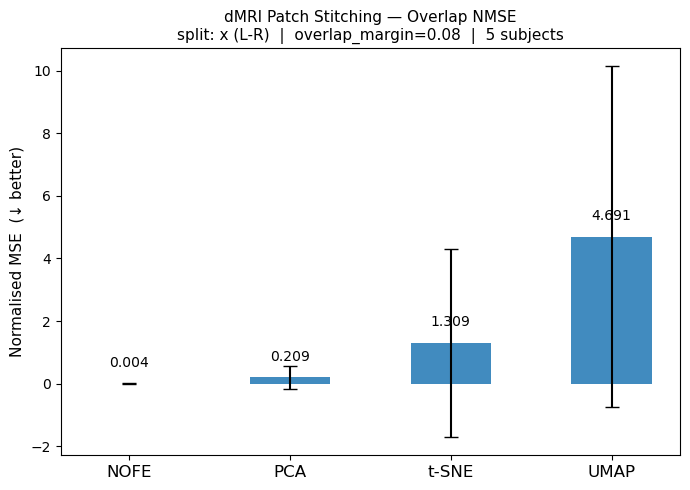

Saved → patch_stitching_dMRI_results.png


In [11]:
if df_results.empty:
    print('No quantitative results to plot.')
else:
    # No custom colours here; let matplotlib use its defaults.
    x = np.arange(len(methods))

    agg   = df_results.groupby('method')['nmse'].agg(['mean', 'std']).reindex(methods)
    means = agg['mean'].values
    stds  = agg['std'].fillna(0).values

    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(x, means, width=0.5, yerr=stds, capsize=5, alpha=0.85)

    offset = max(stds.max(), means.max() * 0.05, 1e-6)
    for bar, v in zip(bars, means):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + offset * 0.08,
            f'{v:.3f}',
            ha='center',
            va='bottom',
            fontsize=10,
        )

    ax.set_xticks(x)
    ax.set_xticklabels([method_labels[m] for m in methods], fontsize=12)
    ax.set_ylabel('Normalised MSE  (↓ better)', fontsize=11)
    ax.set_title(
        f'dMRI Patch Stitching — Overlap NMSE\n'
        f'split: {axis_label}  |  overlap_margin={overlap_margin}  |  {len(test_subjects)} subjects',
        fontsize=11,
    )
    plt.tight_layout()
    plt.savefig(Path.cwd() / 'patch_stitching_dMRI_results.png', dpi=150)
    plt.show()
    print('Saved → patch_stitching_dMRI_results.png')


---
## Save CSV

In [12]:
out = Path.cwd() / 'patch_stitching_dMRI_detailed.csv'
df_results.to_csv(out, index=False)
print(f'Saved → {out.name}')
print(df_results.to_string(index=False))

Saved → patch_stitching_dMRI_detailed.csv
subject      region method     raw_mse      nmse  n_pairs
 134627     frontal   nofe    0.004510  0.002101      150
 134627     frontal    pca   20.317812  0.144735      150
 134627     frontal   tsne 1546.292480 15.123605      150
 134627     frontal   umap   15.619090  0.675313      150
 134627    parietal   nofe    0.076374  0.044962      150
 134627    parietal    pca   20.694838  1.921981      150
 134627    parietal   tsne 2748.636719  1.438314      150
 134627    parietal   umap   38.692593  2.683070      150
 134627    temporal   nofe    0.007090  0.003888      150
 134627    temporal    pca    5.016246  0.064438      150
 134627    temporal   tsne 5760.136230  1.352410      150
 134627    temporal   umap  341.753326 24.214663      150
 134627   occipital   nofe    0.007971  0.004369      150
 134627   occipital    pca   19.452061  0.210295      150
 134627   occipital   tsne 1118.619141  0.482272      150
 134627   occipital   umap   4